# Ejemplo de *detrending*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
def parser(x):
	date_string = '190'+x
	return  pd.to_datetime(date_string, format='%Y-%m')

df = pd.read_csv('shampoo.csv', header=0)
df['Month'] = parser(df['Month'])
df.set_index('Month')

df.head()

,Month,Sales
0,1901-01-01,266.0
1,1901-02-01,145.9
2,1901-03-01,183.1
3,1901-04-01,119.3
4,1901-05-01,180.3


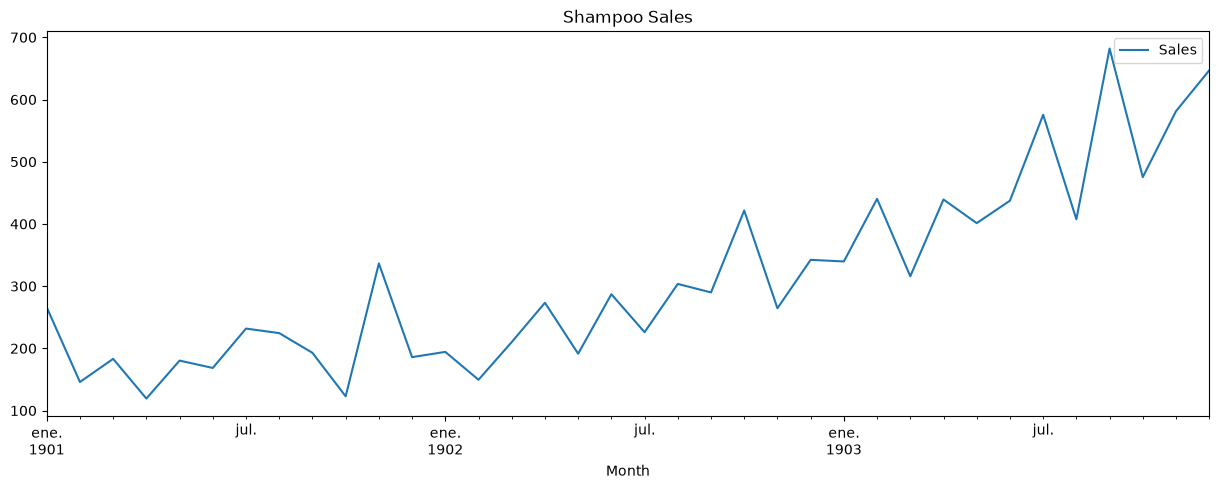

In [10]:
df.plot(figsize=(15,5), title = "Shampoo Sales", x= 'Month', y='Sales')
plt.show()

### 1. Detrending mediante diferenciación de la serie

In [4]:
df_diff = df.diff()

In [5]:
df_diff = df.diff().dropna()

### 2. Detrending mediante eliminación de media móvil

In [ ]:
media_movil = df['Sales'].rolling(window=3).mean() #unicamente la columna numérica
df_detrended = df['Sales'] - media_movil #eliminar tendencia

### 3. Detrending mediante el filtro de Baxter-King
[Link](https://www.statsmodels.org/dev/generated/statsmodels.tsa.filters.bk_filter.bkfilter.html) a la documentación. 
Parámetro de configuración del filtro:
- x: serie temporal que queremos filtrar
- low: Periodo de oscilación mínimo. Se aconseja 6 para datos trimestrales, 1.5 para datos anuales. Como tenemos datos de varios años, le he dado el valor de 1.
- high: Periodo de oscilación máximo. Se aconseja 32 para datos trimestrales, 8 para datos anuales. Como se ve en el ejemplo, he probado varios valores. Se apredia que al aumentar el valor del periodo máximo, aumenta la amplitud de la oscilación. Si podemos el valor a 1, tendremos una línea recta.
- K: Desfase principal a tener en cuenta para el filtro. Se aconseja 12 para datos trimestrales, 3 para datos anuales. Se ha seleccionado 1 para que nos coja toda la serie temporal. Si aumentamos el valor de k, nos filtra un inervalo de la serie temporal menor.

### 4. Detrending mediante aplicación del filtro de [Hodrick-Prescott](https://www.statsmodels.org/stable/generated/statsmodels.tsa.filters.hp_filter.hpfilter.html)

### 5. Detrending meidante [seasonal decompose](https://www.statsmodels.org/dev/generated/statsmodels.tsa.seasonal.seasonal_decompose.html) de Statsmodel 

## Comparación de los resultados

Visualiza todas las series sin tendencia obtenidas a partir de los diferentes métodos.